<a href="https://colab.research.google.com/github/JeffinGeorgePalathingal/Telecom_Customer_Churn_Prediction/blob/main/Project_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

from xgboost import XGBClassifier
import shap

In [2]:
url = "https://raw.githubusercontent.com/JeffinGeorgePalathingal/Telecom_Customer_Churn_Prediction/main/telecom_churn%20%281%29.csv"

df = pd.read_csv(url)

df.head()


,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


Importing the Data

#Data Inspection

In [3]:
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Churn            3333 non-null   int64  
 1   AccountWeeks     3333 non-null   int64  
 2   ContractRenewal  3333 non-null   int64  
 3   DataPlan         3333 non-null   int64  
 4   DataUsage        3333 non-null   float64
 5   CustServCalls    3333 non-null   int64  
 6   DayMins          3333 non-null   float64
 7   DayCalls         3333 non-null   int64  
 8   MonthlyCharge    3333 non-null   float64
 9   OverageFee       3333 non-null   float64
 10  RoamMins         3333 non-null   float64
dtypes: float64(5), int64(6)
memory usage: 286.6 KB


In [5]:
# Checking for missing values
print("Missing values by column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Checking for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values by column:
Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


In [6]:
df.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090,0.276628,0.816475,1.562856,179.775098,100.435644,56.305161,10.051488,10.237294
std,0.352067,39.822106,0.295879,0.447398,1.272668,1.315491,54.467389,20.069084,16.426032,2.535712,2.791840
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,143.700000,87.000000,45.000000,8.330000,8.500000
50%,0.000000,101.000000,1.000000,0.000000,0.000000,1.000000,179.400000,101.000000,53.500000,10.070000,10.300000
75%,0.000000,127.000000,1.000000,1.000000,1.780000,2.000000,216.400000,114.000000,66.200000,11.770000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.800000,165.000000,111.300000,18.190000,20.000000


No missing values or duplicate records were identified

#Exploratory Data Analysis

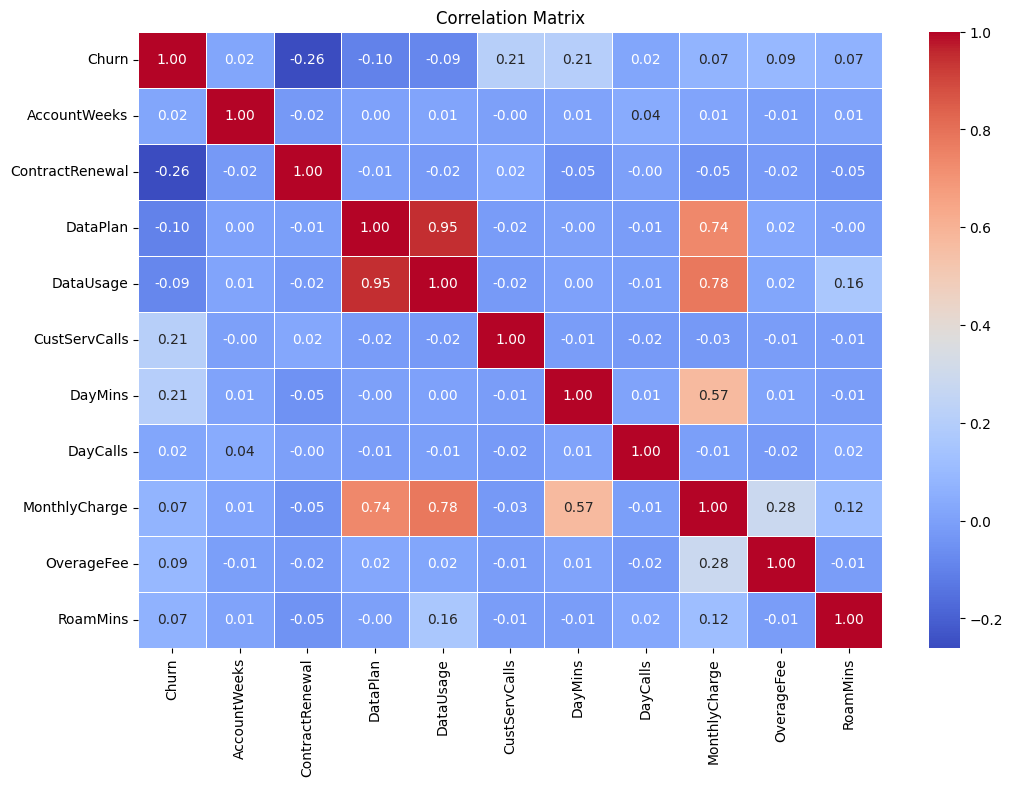

In [7]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix')
plt.show()

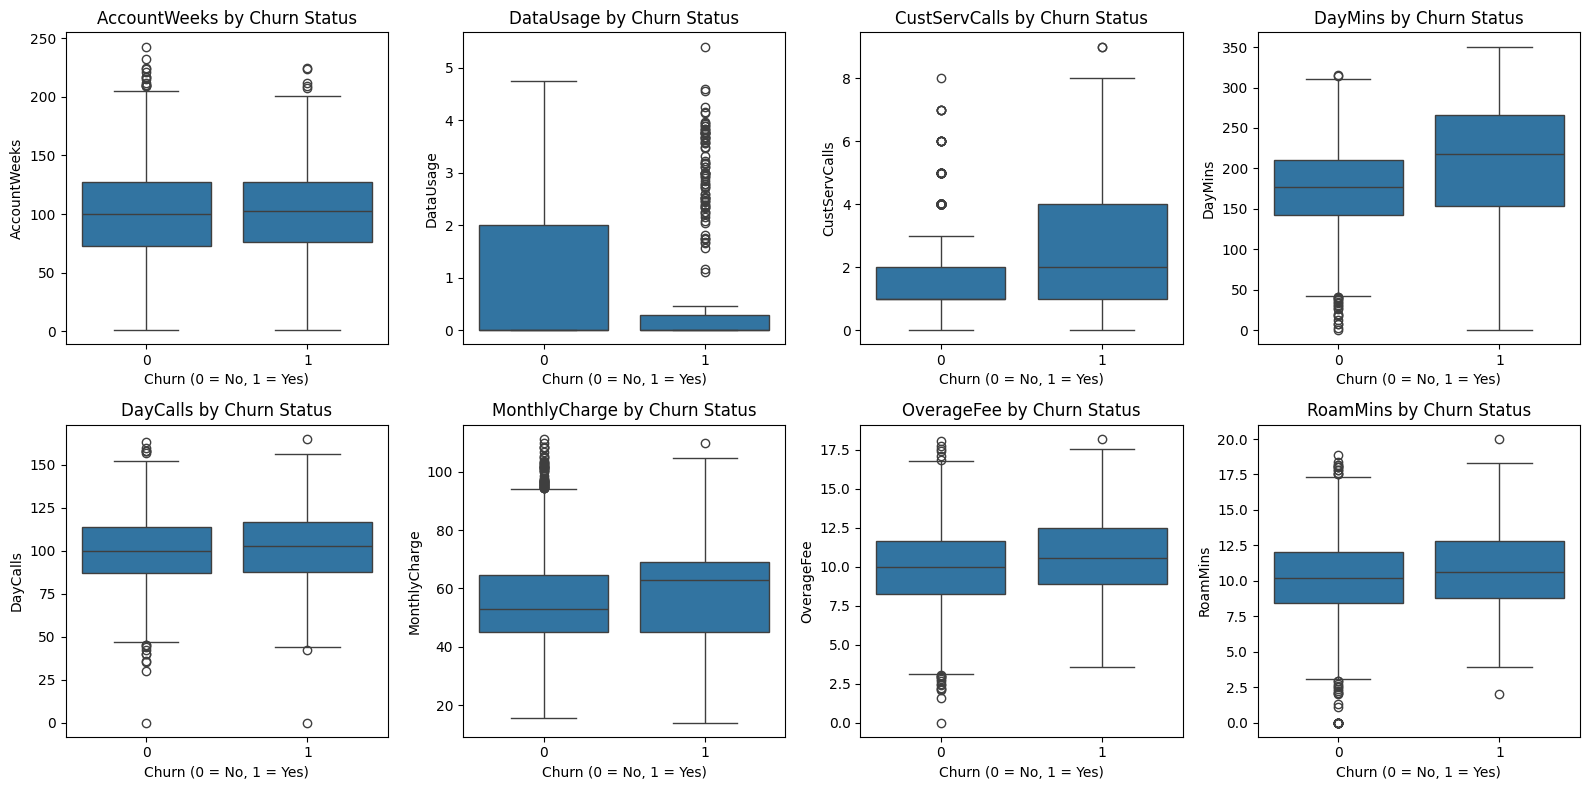

In [8]:
# Numerical variables to compare across churn groups
numerical_features = [
    'AccountWeeks',
    'DataUsage',
    'CustServCalls',
    'DayMins',
    'DayCalls',
    'MonthlyCharge',
    'OverageFee',
    'RoamMins'
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes = axes.flatten()

for i, feature in enumerate(numerical_features):

    sns.boxplot(
        x='Churn',
        y=feature,
        data=df,
        ax=axes[i]
    )

    axes[i].set_title(f'{feature} by Churn Status')
    axes[i].set_xlabel('Churn (0 = No, 1 = Yes)')
    axes[i].set_ylabel(feature)

plt.tight_layout()

plt.show()

Customer Churn Distribution

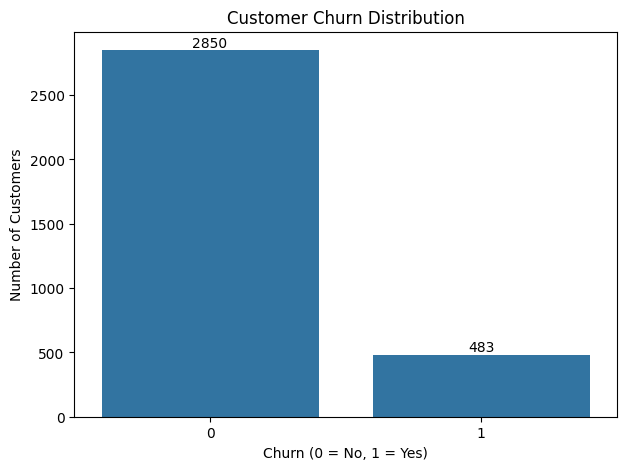

In [9]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x='Churn',
    data=df
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

Observed churn rate by contract renewal status

In [10]:

contract_renewal_churn = (
    df.groupby('ContractRenewal')['Churn']
      .mean()
      .mul(100)
      .reset_index(name='Churn Rate (%)')
)

print("Observed churn rate by contract renewal status:")
print(contract_renewal_churn)

Observed churn rate by contract renewal status:
   ContractRenewal  Churn Rate (%)
0                0       42.414861
1                1       11.495017


#Train-Test Split

Separating the target variable from the features

Since churn distribution is not balanced in the dataset (as seen in above bar graph), stratification is used to maintain a balanced proportion of churners and non-churners in both training and test sets.

In [11]:

X = df.drop('Churn', axis=1)
y = df['Churn']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [13]:
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True))

Training set: (2666, 10)
Testing set: (667, 10)

Training churn distribution:
Churn
0    0.855214
1    0.144786
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    0.854573
1    0.145427
Name: proportion, dtype: float64


#Feature Scaling

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled training data:")
print(X_train_scaled[:5])

Scaled training data:
[[ 0.12573683  0.32521569  1.62544655  2.13561704 -1.20021214  0.74337591
   0.22561073  2.20765376  0.42529354  1.01856546]
 [-0.17530888  0.32521569 -0.61521555 -0.63871437  1.87500705 -0.40129438
   0.22561073 -0.9317981  -0.90591903 -0.80073056]
 [-0.75231315  0.32521569  1.62544655  0.54468688  0.33739745 -0.70494486
   0.32556557 -0.19274426 -0.74744134 -1.65686987]
 [ 0.72782825  0.32521569 -0.61521555 -0.63871437 -1.20021214 -2.04836818
  -0.72396019 -1.66474406 -0.14522613  0.05540874]
 [-0.35091887  0.32521569 -0.61521555 -0.30955641  1.10620225  0.80042539
   0.4255204  -0.18663638 -1.4487051   1.51798005]]


In [15]:
print("Training means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining standard deviations:")
print(X_train_scaled.std(axis=0))

Training means:
[-8.92842522e-17  1.41255683e-16  3.99780234e-17 -7.46256437e-17
 -6.66300390e-17 -1.32260627e-16  2.31872536e-16  5.78348738e-16
 -3.01167776e-16  8.79516515e-16]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Majority-Class Baseline

A majority-class baseline is established as a simple reference point for evaluating the classification models. Since non-churn customers represent the majority class, the baseline predicts `Churn = 0` for every customer.

In [16]:
majority_class = y_train.mode()[0]
baseline_predictions = np.full(len(y_test), majority_class)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"Majority-class baseline accuracy: {baseline_accuracy:.2%}")

Majority-class baseline accuracy: 85.46%


Logistic Regression Model

In [17]:
logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [18]:
y_pred_lr = logistic_model.predict(X_test_scaled)
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

In [19]:
print(y_prob_lr[:10])

[0.22680795 0.05079183 0.08943117 0.08297656 0.34516541 0.04446977
 0.242102   0.0871016  0.05182202 0.06003203]


Evaluating the Logistic Regression Model

In [20]:
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)
f1 = f1_score(y_test, y_pred_lr)
roc_auc = roc_auc_score(y_test, y_prob_lr)

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc * 100:.2f}%")

Accuracy:  85.76%
Precision: 52.63%
Recall:    20.62%
F1 Score:  29.63%
ROC-AUC:   80.91%


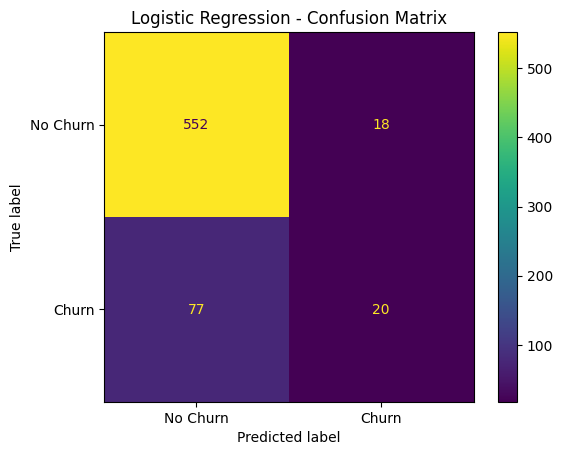

In [21]:
cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

Odds Ratio

In [22]:
odds_ratio_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': logistic_model.coef_[0],
    'Odds Ratio': np.exp(logistic_model.coef_[0])
})

# Sorting by odds ratio in descending order
#Top most shows feature with highest odds
odds_ratio_df = odds_ratio_df.sort_values(
    by='Odds Ratio',
    ascending=False
).reset_index(drop=True)
odds_ratio_df

,Feature,Coefficient,Odds Ratio
0,CustServCalls,0.729021,2.073050
1,DayMins,0.468209,1.597132
2,MonthlyCharge,0.331216,1.392661
3,OverageFee,0.275850,1.317650
4,RoamMins,0.210402,1.234174
5,DayCalls,0.082490,1.085988
6,AccountWeeks,0.034709,1.035319
7,DataUsage,-0.007387,0.992640
8,ContractRenewal,-0.579097,0.560404
9,DataPlan,-0.665027,0.514260


ROC Curve

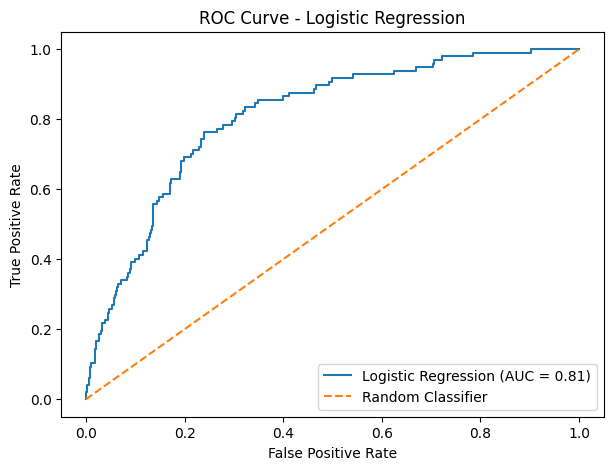

In [23]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.2f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

Random Forest

In [24]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [25]:
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [26]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy:  {accuracy_rf * 100:.2f}%")
print(f"Precision: {precision_rf * 100:.2f}%")
print(f"Recall:    {recall_rf * 100:.2f}%")
print(f"F1 Score:  {f1_rf * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc_rf * 100:.2f}%")

Accuracy:  92.50%
Precision: 82.19%
Recall:    61.86%
F1 Score:  70.59%
ROC-AUC:   86.32%


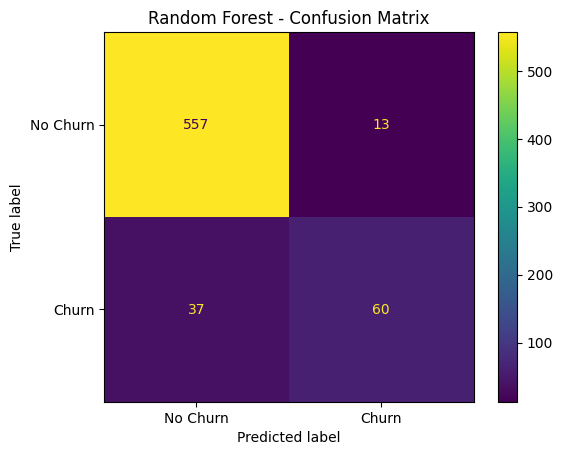

In [27]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [28]:
# Getting feature importance from the Random Forest model
rf_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})
rf_importance_df = rf_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

rf_importance_df

,Feature,Importance
0,DayMins,0.198161
1,MonthlyCharge,0.173206
2,CustServCalls,0.144752
3,OverageFee,0.090550
4,RoamMins,0.082399
5,DataUsage,0.078004
6,ContractRenewal,0.070632
7,AccountWeeks,0.061990
8,DayCalls,0.061109
9,DataPlan,0.039197


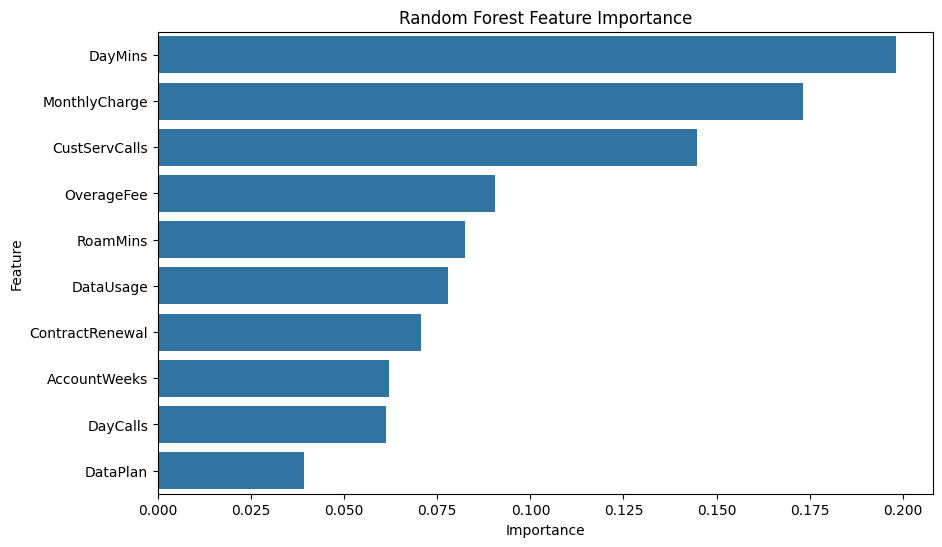

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

Shap Interaction Values

In [30]:
explainer = shap.TreeExplainer(rf_model)
shap_interaction_values = explainer.shap_interaction_values(X_test)

In [31]:
print(type(shap_interaction_values))
print(np.array(shap_interaction_values).shape)

<class 'numpy.ndarray'>
(667, 10, 10, 2)


In [32]:
# Select SHAP interaction values for the Churn class
interaction_values = shap_interaction_values[:, :, :, 1]

print("Interaction values shape:", interaction_values.shape)

Interaction values shape: (667, 10, 10)


In [33]:
# Calculate mean absolute interaction strength
mean_interactions = np.abs(interaction_values).mean(axis=0)

interaction_df = pd.DataFrame(
    mean_interactions,
    index=X_test.columns,
    columns=X_test.columns
)

# Removing the diagonal because these represent individual feature effects
np.fill_diagonal(interaction_df.values, 0)

# Extracting unique feature pairs
interaction_pairs = (
    interaction_df
    .where(np.triu(np.ones(interaction_df.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

interaction_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Interaction Importance'
]

# Sort from strongest to weakest interaction
interaction_pairs = interaction_pairs.sort_values(
    by='Interaction Importance',
    ascending=False
).reset_index(drop=True)

interaction_pairs.head(10)

,Feature 1,Feature 2,Interaction Importance
0,DataUsage,MonthlyCharge,0.024399
1,DataPlan,MonthlyCharge,0.015781
2,CustServCalls,MonthlyCharge,0.012297
3,ContractRenewal,RoamMins,0.011460
4,DayMins,MonthlyCharge,0.010133
5,CustServCalls,DayMins,0.010048
6,DayMins,OverageFee,0.007628
7,DataUsage,DayMins,0.006504
8,DataPlan,DayMins,0.004742
9,ContractRenewal,MonthlyCharge,0.004564


XGBoost Model

In [34]:
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss'
)

In [35]:
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [36]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print(f"Accuracy:  {accuracy_xgb * 100:.2f}%")
print(f"Precision: {precision_xgb * 100:.2f}%")
print(f"Recall:    {recall_xgb * 100:.2f}%")
print(f"F1 Score:  {f1_xgb * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc_xgb * 100:.2f}%")

Accuracy:  91.75%
Precision: 75.61%
Recall:    63.92%
F1 Score:  69.27%
ROC-AUC:   82.49%


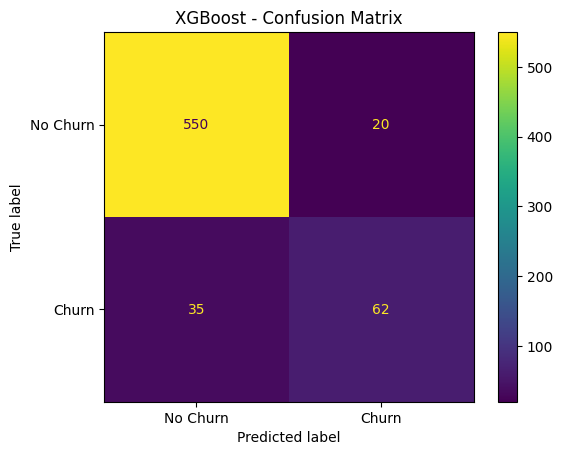

In [37]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title('XGBoost - Confusion Matrix')
plt.show()

In [38]:
# Getting feature importance from the XGBoost model
xgb_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
})

xgb_importance_df = xgb_importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

xgb_importance_df

,Feature,Importance
0,DataPlan,0.699617
1,ContractRenewal,0.099548
2,CustServCalls,0.056710
3,DayMins,0.041561
4,MonthlyCharge,0.031375
5,DataUsage,0.018112
6,RoamMins,0.017589
7,OverageFee,0.014855
8,DayCalls,0.011548
9,AccountWeeks,0.009083


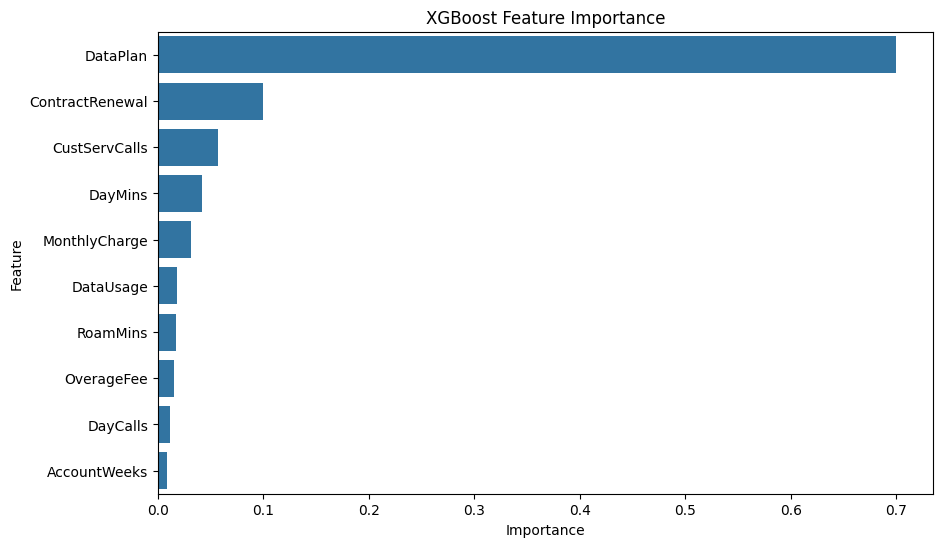

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_importance_df,
    x='Importance',
    y='Feature'
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [40]:
# Customer count and churn rate by DataPlan
dataplan_analysis = df.groupby('DataPlan').agg(
    Customers=('Churn', 'count'),
    Churn_Rate=('Churn', 'mean')
)

dataplan_analysis['Churn_Rate'] *= 100

dataplan_analysis

,Customers,Churn_Rate
DataPlan,,
0,2411,16.715056
1,922,8.676790


Model Comparison

In [41]:
model_comparison = pd.DataFrame({
    'Model': [
        'Majority-Class Baseline',
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        baseline_accuracy,
        accuracy,
        accuracy_rf,
        accuracy_xgb
    ],
    'Precision': [
        np.nan,
        precision,
        precision_rf,
        precision_xgb
    ],
    'Recall': [
        np.nan,
        recall,
        recall_rf,
        recall_xgb
    ],
    'F1 Score': [
        np.nan,
        f1,
        f1_rf,
        f1_xgb
    ],
    'ROC-AUC': [
        np.nan,
        roc_auc,
        roc_auc_rf,
        roc_auc_xgb
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Majority-Class Baseline,0.854573,NaN,NaN,NaN,NaN
1,Logistic Regression,0.857571,0.526316,0.206186,0.296296,0.809116
2,Random Forest,0.925037,0.821918,0.618557,0.705882,0.863185
3,XGBoost,0.917541,0.756098,0.639175,0.692737,0.824851


#PROBABILITY OF CHURN

#Customer Risk Scoring

Customers who have not churned are scored using the trained Random Forest model to calculate their predicted probability of churn. The trained model is applied to the full customer dataset to find potential existing customers who are at risk of churn.

In [42]:
churn_probability = rf_model.predict_proba(X)[:, 1]

df['Churn_Probability'] = churn_probability


df['Churn_Probability_%'] = df['Churn_Probability'] * 100

df[['Churn', 'Churn_Probability_%']].head()

,Churn,Churn_Probability_%
0,0,0.0
1,0,9.0
2,0,1.0
3,0,20.0
4,0,19.0


#Highest Risk Customers

In [43]:
# Filtering for customers who have not churned

high_risk_existing = df[df['Churn'] == 0].sort_values(
    by='Churn_Probability',
    ascending=False
)

# 10 highest-risk existing customers
high_risk_existing.head(10)



,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins,Churn_Probability,Churn_Probability_%
112,0,98,1,0,0.00,4,161.0,117,44.0,9.55,12.1,0.93,93.0
1095,0,106,1,0,0.00,1,274.4,120,64.0,9.93,6.0,0.90,90.0
989,0,178,1,0,0.00,1,275.4,150,63.0,9.38,13.6,0.88,88.0
974,0,21,1,1,2.57,6,135.9,90,72.7,13.55,9.5,0.74,74.0
2622,0,86,1,1,3.13,4,144.8,105,74.3,10.31,11.6,0.69,69.0
2721,0,50,1,0,0.29,1,295.3,127,64.9,6.37,9.6,0.63,63.0
1210,0,48,1,0,0.20,1,275.2,67,65.0,9.01,7.9,0.61,61.0
338,0,77,1,0,0.00,2,233.8,104,63.0,13.33,7.6,0.60,60.0
184,0,170,0,0,0.00,3,259.9,68,66.0,12.25,8.4,0.56,56.0
1010,0,105,1,0,0.00,0,246.4,83,64.0,12.81,3.8,0.55,55.0


In [44]:
# Focussing on the top 10% highest-risk customers who have not churned
risk_threshold = high_risk_existing['Churn_Probability'].quantile(0.90)

top_risk_group = high_risk_existing[
    high_risk_existing['Churn_Probability'] >= risk_threshold
]

print("Number of high-risk customers:", len(top_risk_group))
print("Risk probability threshold:", risk_threshold)

Number of high-risk customers: 288
Risk probability threshold: 0.1


In [45]:
other_customers = high_risk_existing[
    high_risk_existing['Churn_Probability'] < risk_threshold]

In [46]:
top_risk_group.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins,Churn_Probability,Churn_Probability_%
count,288.0,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000
mean,0.0,100.215278,0.586806,0.232639,0.675347,1.930556,193.515278,98.559028,57.996528,10.504896,9.928472,0.212604,21.260417
std,0.0,42.431443,0.493264,0.423249,1.158549,1.649212,61.892047,22.390811,14.495353,2.793254,2.919385,0.136705,13.670522
min,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000,2.460000,0.000000,0.100000,10.000000
25%,0.0,68.750000,0.000000,0.000000,0.000000,1.000000,151.350000,83.000000,47.750000,8.597500,8.300000,0.120000,12.000000
50%,0.0,100.000000,1.000000,0.000000,0.000000,1.000000,197.650000,99.000000,59.650000,10.580000,10.050000,0.160000,16.000000
75%,0.0,129.000000,1.000000,0.000000,0.355000,3.000000,245.225000,114.000000,64.825000,12.480000,11.700000,0.242500,24.250000
max,0.0,217.000000,1.000000,1.000000,4.640000,8.000000,310.400000,150.000000,102.900000,17.710000,18.200000,0.930000,93.000000


In [47]:
print("Average DayMins:", top_risk_group['DayMins'].mean())
print("Average MonthlyCharge:", top_risk_group['MonthlyCharge'].mean())
print("Average CustServCalls:", top_risk_group['CustServCalls'].mean())
print("Average OverageFee:", top_risk_group['OverageFee'].mean())
print("Average RoamMins:", top_risk_group['RoamMins'].mean())
print("DataPlan rate:", top_risk_group['DataPlan'].mean() * 100, "%")
print("ContractRenewal rate:", top_risk_group['ContractRenewal'].mean() * 100, "%")

Average DayMins: 193.51527777777778
Average MonthlyCharge: 57.99652777777778
Average CustServCalls: 1.9305555555555556
Average OverageFee: 10.504895833333332
Average RoamMins: 9.928472222222222
DataPlan rate: 23.26388888888889 %
ContractRenewal rate: 58.68055555555556 %


In [48]:
# Comparing the mean and standard deviation for the two groups
comparison_stats = pd.DataFrame({
    'Top 10% High-Risk Mean': top_risk_group.mean(numeric_only=True),
    'Top 10% High-Risk SD': top_risk_group.std(numeric_only=True),
    'Other 90% Mean': other_customers.mean(numeric_only=True),
    'Other 90% SD': other_customers.std(numeric_only=True)
})

comparison_stats = comparison_stats.loc[
    [
        'DayMins',
        'MonthlyCharge',
        'CustServCalls',
        'OverageFee',
        'RoamMins',
        'DataUsage',
        'AccountWeeks',
        'DayCalls',
        'DataPlan',
        'ContractRenewal'
    ]
]

comparison_stats

,Top 10% High-Risk Mean,Top 10% High-Risk SD,Other 90% Mean,Other 90% SD
DayMins,193.515278,61.892047,173.114169,48.270372
MonthlyCharge,57.996528,14.495353,55.571155,16.627988
CustServCalls,1.930556,1.649212,1.395785,1.083163
OverageFee,10.504896,2.793254,9.892760,2.474311
RoamMins,9.928472,2.919385,10.184778,2.768310
DataUsage,0.675347,1.158549,0.883150,1.298177
AccountWeeks,100.215278,42.431443,100.858704,39.593773
DayCalls,98.559028,22.390811,100.476971,19.483903
DataPlan,0.232639,0.423249,0.302498,0.459429
ContractRenewal,0.586806,0.493264,0.973849,0.159617


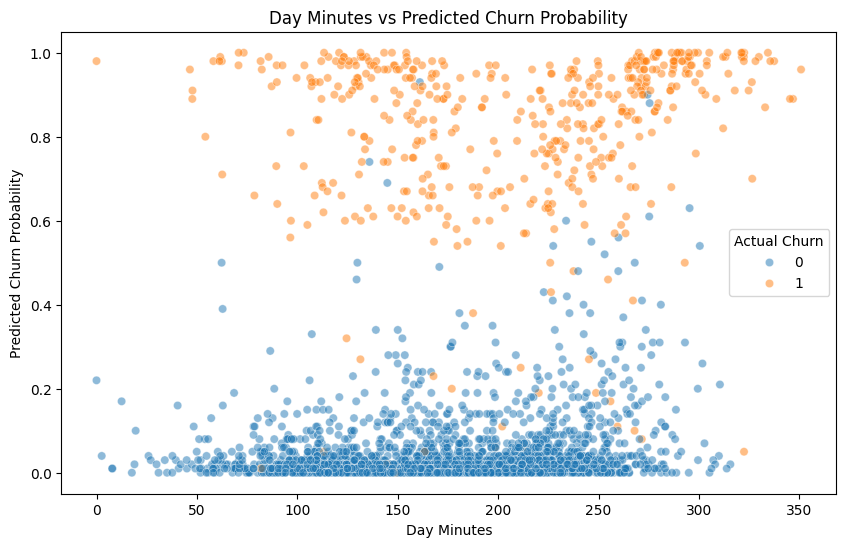

In [49]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='DayMins',
    y='Churn_Probability',
    hue='Churn',
    alpha=0.5
)

plt.title('Day Minutes vs Predicted Churn Probability')
plt.xlabel('Day Minutes')
plt.ylabel('Predicted Churn Probability')
plt.legend(title='Actual Churn')

plt.show()

#CUSTOMER GROUPS AT RISK

# Group 1 - Contract risk customers

In [50]:
# Predicted churn probability by contract renewal status
contract_risk = df[df['Churn'] == 0].groupby('ContractRenewal')[
    'Churn_Probability'
].mean() * 100

contract_risk

,Churn_Probability
ContractRenewal,
0,13.860215
1,2.933559


#Group 2 - Customers with frequent customer-service calls

In [51]:
# Create customer service contact groups
df['High_CustServCalls'] = (df['CustServCalls'] >= 2).astype(int)

# Compare predicted churn probability
service_risk = df[df['Churn'] == 0].groupby(
    'High_CustServCalls'
)['Churn_Probability'].mean() * 100

service_risk

,Churn_Probability
High_CustServCalls,
0,3.261418
1,4.187184


#Group 3 - Higher-usage customers without a data plan

In [52]:
# Calculate the 75th percentile of daytime usage
daymins_threshold = df['DayMins'].quantile(0.75)

print("High DayMins threshold:", daymins_threshold)

High DayMins threshold: 216.4


In [53]:
# High usage + no data plan
high_usage_no_plan = df[
    (df['Churn'] == 0) &
    (df['DayMins'] >= daymins_threshold) &
    (df['DataPlan'] == 0)
]

# Average predicted churn probability
high_usage_no_plan['Churn_Probability'].mean() * 100

np.float64(9.312997347480106)

In [54]:
# Calculate average predicted churn probability for each high-risk segment

contract_no_renewal = df[
    (df['Churn'] == 0) &
    (df['ContractRenewal'] == 0)
]['Churn_Probability'].mean() * 100

frequent_service = df[
    (df['Churn'] == 0) &
    (df['CustServCalls'] >= 2)
]['Churn_Probability'].mean() * 100

high_usage_no_plan_prob = df[
    (df['Churn'] == 0) &
    (df['DayMins'] >= daymins_threshold) &
    (df['DataPlan'] == 0)
]['Churn_Probability'].mean() * 100

segment_risk = pd.DataFrame({
    'Customer Group': [
        'No Contract Renewal',
        '2+ Customer Service Calls',
        'High DayMins + No Data Plan'
    ],
    'Customers': [
        len(df[(df['Churn'] == 0) & (df['ContractRenewal'] == 0)]),
        len(df[(df['Churn'] == 0) & (df['CustServCalls'] >= 2)]),
        len(df[
            (df['Churn'] == 0) &
            (df['DayMins'] >= daymins_threshold) &
            (df['DataPlan'] == 0)
        ])
    ],
    'Average Predicted Churn Probability (%)': [
        contract_no_renewal,
        frequent_service,
        high_usage_no_plan_prob
    ]
})

segment_risk.sort_values(
    by='Average Predicted Churn Probability (%)',
    ascending=False
).reset_index(drop=True)

,Customer Group,Customers,Average Predicted Churn Probability (%)
0,No Contract Renewal,186,13.860215
1,High DayMins + No Data Plan,377,9.312997
2,2+ Customer Service Calls,1186,4.187184


#Conclusion

Three classification models were evaluated, with Random Forest providing the strongest overall performance based on the evaluation metrics.

The final risk analysis showed how model predictions can be translated into actionable customer segments, helping identify customers who may require targeted retention efforts.